Visualize hierarchical and clustering relationships using dendrograms and agglomerative clustering, helping to uncover nested data structures and inform segmentation strategies.


In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 150

In [4]:
data = {
    'annual_spend': np.random.normal(5000, 1500, n_samples),
    'purchase_frequency': np.random.poisson(lam=12, size=n_samples),
    'avg_order_value': np.random.normal(350, 80, n_samples),
    'support_tickets': np.random.poisson(lam=2, size=n_samples),
    'discount_sensitivity': np.random.uniform(0.05, 0.45, n_samples)
}

In [5]:
df_customers = pd.DataFrame(data)

In [6]:
print(df_customers.head())

   annual_spend  purchase_frequency  avg_order_value  support_tickets  \
0   5745.071230                  13       294.021959                1   
1   4792.603548                  13       367.118393                2   
2   5971.532807                   7       341.013756                6   
3   7284.544785                  12       332.322432                3   
4   4648.769938                  14       399.133336                3   

   discount_sensitivity  
0              0.358369  
1              0.387913  
2              0.354410  
3              0.300488  
4              0.102498  


In [7]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist, squareform

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_customers)

In [9]:
dist_matrix = pdist(X_scaled, metric='euclidean')

In [10]:
print("Scaled features shape:", X_scaled.shape)
print("Pairwise distance vector shape:", dist_matrix.shape)

Scaled features shape: (150, 5)
Pairwise distance vector shape: (11175,)


In [11]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

In [12]:
linkage_matrix = linkage(X_scaled, method='ward')

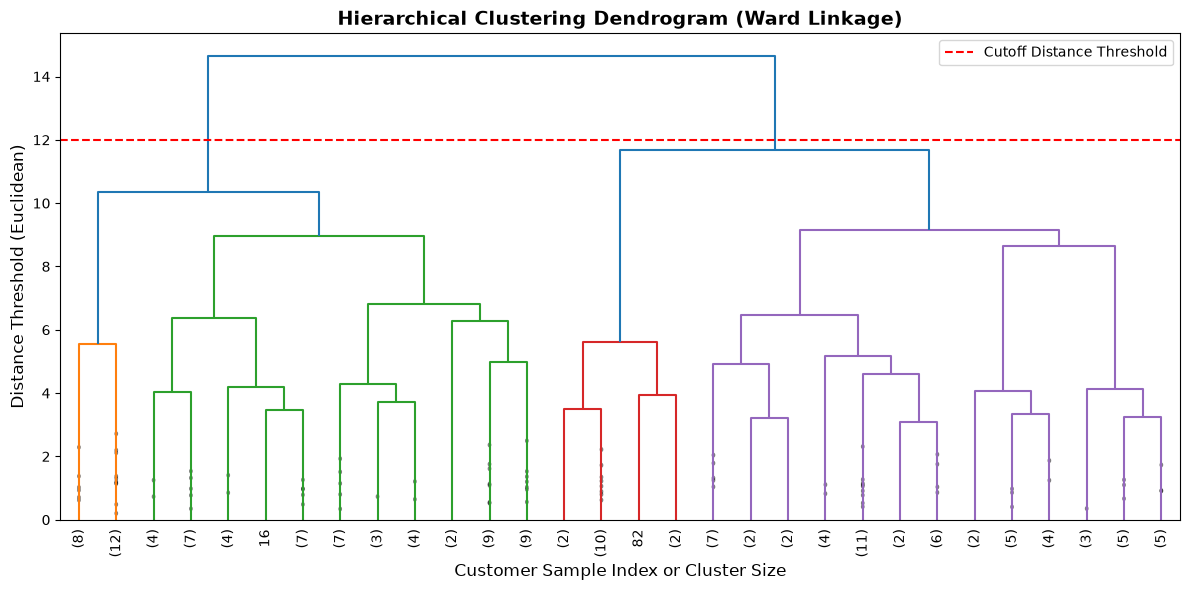

In [18]:
linkage_matrix = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))

dendro = dendrogram(
    linkage_matrix,
    truncate_mode='lastp',  
    p=30,                  
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)

plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=14, fontweight='bold')
plt.xlabel('Customer Sample Index or Cluster Size', fontsize=12)
plt.ylabel('Distance Threshold (Euclidean)', fontsize=12)
plt.axhline(y=12, color='r', linestyle='--', label='Cutoff Distance Threshold')
plt.legend(loc='upper right')
plt.tight_layout()

plt.show()

In [19]:
from sklearn.cluster import AgglomerativeClustering

In [20]:
n_clusters = 3
agg_cluster = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')

In [21]:
df_customers['cluster_label'] = agg_cluster.fit_predict(X_scaled)

In [22]:
cluster_profiles = df_customers.groupby('cluster_label').mean()

In [23]:
print(cluster_profiles.round(2))

               annual_spend  purchase_frequency  avg_order_value  \
cluster_label                                                      
0                   4369.96               13.31           363.94   
1                   5103.91                9.45           323.08   
2                   6597.49               10.47           327.95   

               support_tickets  discount_sensitivity  
cluster_label                                         
0                         2.34                  0.19  
1                         1.12                  0.28  
2                         3.80                  0.36  
